# K-Means Clustering and Elbow Method
Football Players Stats 2025-2026

Plan: clean the data, make per-90 stats, scale them, build K-Means from scratch, find k using the elbow method (also from scratch), then look at what the clusters mean.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported")

Libraries imported


In [2]:
df = pd.read_csv("football_players_stats.csv")
print(df.shape)

(523, 14)


In [3]:
df.head()

,Player,Squad,Pos,Age,MP,Min,Gls,Ast,Sh,SoT,PrgC,PrgP,Tkl,Int
0,Tariq Torres,Ironwood,DF,31,20,1422,0,4,14,14,128.0,139,18.0,8
1,Mateo Lindqvist,Bayview Athletic,MF,36,20,1758,0,0,10,2,NaN,133,31.0,84
2,Sami Santos,Northvale FC,FW,22,20,1628,11,3,36,19,39.0,43,21.0,9
3,Nico Fischer,Kingsbridge,MF,33,14,1265,1,3,12,7,35.0,42,26.0,21
4,Liam Duarte,Valtora,FW,21,16,1118,2,2,53,15,20.0,34,8.0,5


In [4]:
df.columns.tolist()

['Player',
 'Squad',
 'Pos',
 'Age',
 'MP',
 'Min',
 'Gls',
 'Ast',
 'Sh',
 'SoT',
 'PrgC',
 'PrgP',
 'Tkl',
 'Int']

Column names can be different in the real file, so check this list first and change the names below if needed.

In [5]:
df.dtypes

Player        str
Squad         str
Pos           str
Age         int64
MP          int64
Min         int64
Gls         int64
Ast         int64
Sh          int64
SoT         int64
PrgC      float64
PrgP        int64
Tkl       float64
Int         int64
dtype: object

In [6]:
df.isnull().sum().sort_values(ascending=False).head(15)

PrgC      4
Tkl       3
Pos       0
Age       0
Player    0
Squad     0
Min       0
MP        0
Gls       0
Ast       0
SoT       0
Sh        0
PrgP      0
Int       0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(3)

## Cleaning

Three things we are doing here:
- remove duplicates
- remove goalkeepers, their stats are totally different (saves, clean sheets) and they would make their own cluster
- keep only players with enough minutes, someone who played 20 minutes can have crazy per 90 numbers

In [8]:
df = df.drop_duplicates()

df = df[df["Pos"] != "GK"]
print("After removing GK:", df.shape)

df = df[df["Min"] >= 450].reset_index(drop=True)
print("After minutes filter:", df.shape)

After removing GK: (471, 14)
After minutes filter: (398, 14)


450 minutes is around 5 full matches. Can change this later if too many players are getting removed.

In [9]:
df["Pos"].value_counts()

Pos
DF    161
MF    136
FW    101
Name: count, dtype: int64

## Per 90 stats

Players who played more will have more goals, tackles etc just because of more time on the pitch. So we divide everything by (minutes / 90) to compare style and not playing time.

In [10]:
raw_stats = ["Gls", "Ast", "Sh", "SoT", "PrgC", "PrgP", "Tkl", "Int"]

df = df.dropna(subset=raw_stats + ["Min"]).reset_index(drop=True)

nineties = df["Min"] / 90

for col in raw_stats:
    df[col + "_p90"] = df[col] / nineties

features = [col + "_p90" for col in raw_stats]
df[features].describe()

,Gls_p90,Ast_p90,Sh_p90,SoT_p90,PrgC_p90,PrgP_p90,Tkl_p90,Int_p90
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,0.181387,0.145195,1.425691,0.497323,2.067679,5.106044,2.133170,1.453579
std,0.249852,0.163719,1.154291,0.498606,1.856329,3.450481,1.709530,1.127672
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.871530,0.000000,0.000000
25%,0.000000,0.000000,0.573027,0.166629,0.859007,2.711227,0.955825,0.560125
50%,0.089823,0.107979,1.099787,0.325307,1.592379,4.268770,1.670677,1.248772
75%,0.215095,0.206284,1.963582,0.641977,2.609760,6.248615,2.858935,1.950476
max,1.523579,0.910624,5.717916,3.217666,16.507177,28.217507,12.926391,6.298343


Features used:
- attacking: goals, shots, shots on target
- creating: assists, progressive passes, progressive carries
- defending: tackles, interceptions

We are not using the position column as a feature. We keep it only to check the clusters later.

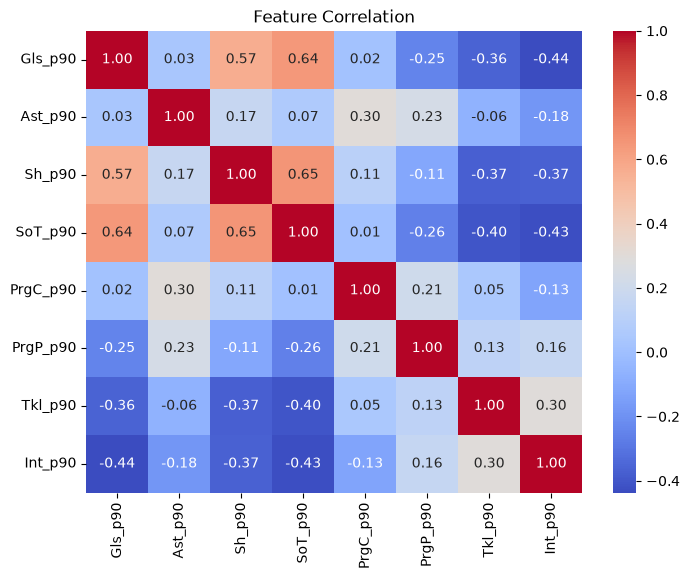

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

If two features have really high correlation (like above 0.85) then one of them is basically repeating the other, so we can drop one. Shots and shots on target are usually close, so keep an eye on those.

In [12]:
X = df[features].to_numpy(dtype=float)
X.shape

(392, 8)

## Scaling

K-Means uses distance, so a feature with big numbers will take over. We scale every feature to mean 0 and std 1.

In [13]:
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)

X_std[X_std == 0] = 1

X_scaled = (X - X_mean) / X_std

print(X_scaled.mean(axis=0).round(2))
print(X_scaled.std(axis=0).round(2))

[-0.  0.  0.  0. -0.  0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1.]


Means are 0 and stds are 1 so scaling worked.

## K-Means from scratch

How it works:
1. pick k starting centroids (using kmeans++, explained below)
2. give every player to the nearest centroid
3. move each centroid to the average of its players
4. repeat 2 and 3 until centroids stop moving

kmeans++ is just a smarter way to pick the starting points. First centroid is random, then the next ones are picked far away from the ones we already have, so we don't start with two centroids sitting in the same place.

I am also running it a few times (n_init) and keeping the best one, because bad starting centroids can give a bad result.

In [14]:
class KMeans:
    def __init__(self, k=3, max_iter=100, tol=1e-4, n_init=10, seed=42):
        self.k = k
        self.max_iter = max_iter
        self.tol = tol
        self.n_init = n_init
        self.rng = np.random.default_rng(seed)

    def init_centroids(self, X):
        # kmeans++ : first centroid is random, the rest are picked far from the ones already chosen
        centroids = [X[self.rng.integers(len(X))]]

        for _ in range(1, self.k):
            # squared distance of every point to its nearest chosen centroid
            d2 = np.min([np.sum((X - c) ** 2, axis=1) for c in centroids], axis=0)
            probs = d2 / d2.sum()
            centroids.append(X[self.rng.choice(len(X), p=probs)])

        return np.array(centroids)

    def assign_clusters(self, X, centroids):
        # distance of every point from every centroid
        distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
        return np.argmin(distances, axis=1)

    def update_centroids(self, X, labels, old_centroids):
        new_centroids = old_centroids.copy()
        for i in range(self.k):
            points = X[labels == i]
            # if a cluster gets empty just keep the old centroid
            if len(points) > 0:
                new_centroids[i] = points.mean(axis=0)
        return new_centroids

    def run_once(self, X):
        centroids = self.init_centroids(X)

        for _ in range(self.max_iter):
            labels = self.assign_clusters(X, centroids)
            new_centroids = self.update_centroids(X, labels, centroids)

            shift = np.linalg.norm(new_centroids - centroids)
            centroids = new_centroids
            if shift < self.tol:
                break

        labels = self.assign_clusters(X, centroids)
        inertia = np.sum((X - centroids[labels]) ** 2)
        return centroids, labels, inertia

    def fit(self, X):
        best_inertia = np.inf

        for _ in range(self.n_init):
            centroids, labels, inertia = self.run_once(X)
            if inertia < best_inertia:
                best_inertia = inertia
                self.centroids_ = centroids
                self.labels_ = labels
                self.inertia_ = inertia

        return self

    def predict(self, X):
        return self.assign_clusters(X, self.centroids_)

Inertia is the sum of squared distances between each player and their centroid. Lower means players are closer to their own centroid.

In [15]:
test_model = KMeans(k=4).fit(X_scaled)

print("Inertia:", test_model.inertia_)
print("Players per cluster:", np.bincount(test_model.labels_))

Inertia: 1739.0701754346824
Players per cluster: [ 56  70 183  83]


## Elbow method

We run K-Means for k = 1 to 10 and note the inertia each time. Inertia always goes down when k goes up, so we look for the point where the drop becomes small. That bend is the elbow.

In [16]:
def elbow_curve(X, max_k=10):
    inertias = []
    for k in range(1, max_k + 1):
        model = KMeans(k=k).fit(X)
        inertias.append(model.inertia_)
        print("k =", k, "| inertia =", round(model.inertia_, 2))
    return inertias

In [17]:
inertias = elbow_curve(X_scaled, max_k=10)

k = 1 | inertia = 3136.0
k = 2 | inertia = 2267.32
k = 3 | inertia = 1911.01
k = 4 | inertia = 1739.07
k = 5 | inertia = 1597.25
k = 6 | inertia = 1475.35
k = 7 | inertia = 1370.44
k = 8 | inertia = 1305.04
k = 9 | inertia = 1220.95
k = 10 | inertia = 1160.75


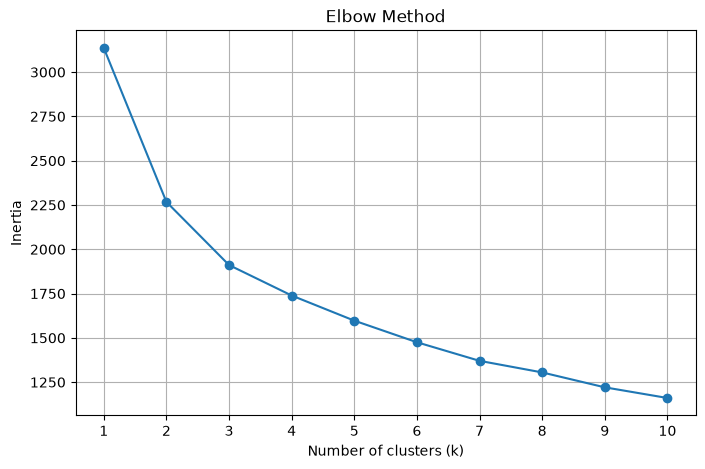

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [19]:
drops = -np.diff(inertias)

for k in range(2, 11):
    print("k", k - 1, "->", k, "| drop:", round(drops[k - 2], 2))

k 1 -> 2 | drop: 868.68
k 2 -> 3 | drop: 356.31
k 3 -> 4 | drop: 171.94
k 4 -> 5 | drop: 141.82
k 5 -> 6 | drop: 121.9
k 6 -> 7 | drop: 104.91
k 7 -> 8 | drop: 65.4
k 8 -> 9 | drop: 84.09
k 9 -> 10 | drop: 60.2


The drop is big in the beginning and then slows down. The elbow is around k = 4 or 5 (change this after looking at your own plot). After that, adding more clusters doesn't help much.

Elbow is not always clear so we also keep football sense in mind. Too many clusters will just split similar players.

## Final model

In [20]:
k = 5

model = KMeans(k=k, n_init=20).fit(X_scaled)
df["cluster"] = model.labels_

print("Inertia:", model.inertia_)
df["cluster"].value_counts().sort_index()

Inertia: 1597.2512686836608


cluster
0     62
1    161
2     52
3     47
4     70
Name: count, dtype: int64

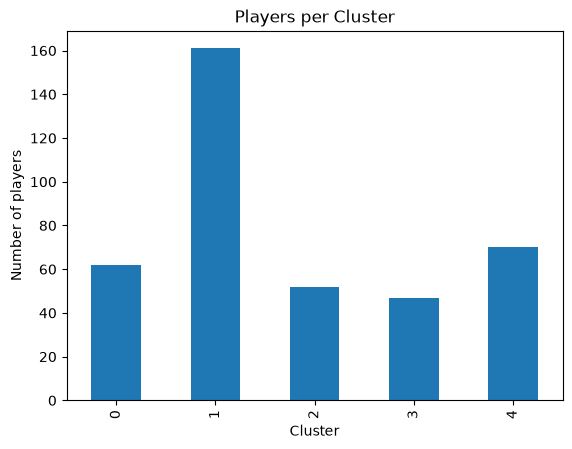

In [21]:
df["cluster"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Cluster")
plt.ylabel("Number of players")
plt.title("Players per Cluster")
plt.show()

## Understanding the clusters

Average per 90 stats of each cluster. We use the original values here (not scaled) so numbers are easy to read.

In [22]:
profile = df.groupby("cluster")[features].mean().round(2)
profile

,Gls_p90,Ast_p90,Sh_p90,SoT_p90,PrgC_p90,PrgP_p90,Tkl_p90,Int_p90
cluster,,,,,,,,
0,0.09,0.30,1.54,0.32,2.30,10.44,1.74,1.45
1,0.06,0.06,0.74,0.24,1.11,3.91,2.25,1.94
2,0.66,0.11,3.25,1.47,1.48,2.68,0.63,0.37
3,0.08,0.13,0.82,0.24,3.20,6.62,5.22,2.09
4,0.26,0.23,1.95,0.70,3.74,3.91,1.25,0.71


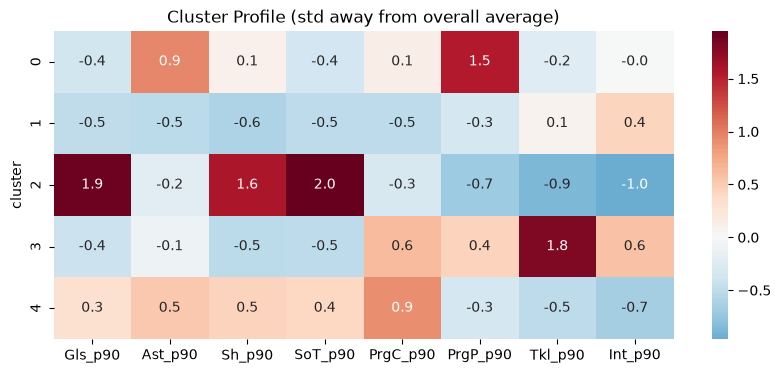

In [23]:
profile_z = (profile - df[features].mean()) / df[features].std()

plt.figure(figsize=(10, 4))
sns.heatmap(profile_z, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Cluster Profile (std away from overall average)")
plt.show()

Red means the cluster is high in that stat and blue means low. Now we can name each cluster by looking at its row.

Cluster 0:
Cluster 1:
Cluster 2:
Cluster 3:
Cluster 4:

(fill these after checking the heatmap)

In [24]:
pd.crosstab(df["cluster"], df["Pos"], normalize="index").round(2)

Pos,DF,FW,MF
cluster,,,
0,0.35,0.02,0.63
1,0.58,0.01,0.42
2,0.00,1.00,0.00
3,0.70,0.00,0.30
4,0.14,0.66,0.20


This shows what percent of each cluster has which position. We never gave position to the model, so if a cluster is mostly FW then the model found strikers by itself using only stats.

In [25]:
for c in range(k):
    idx = np.where(model.labels_ == c)[0]
    dist = np.linalg.norm(X_scaled[idx] - model.centroids_[c], axis=1)
    closest = idx[np.argsort(dist)[:5]]
    print("Cluster", c, ":", df.loc[closest, "Player"].tolist())

Cluster 0 : ['Diego Mendes', 'Ivan Keller', 'Yusuf Kovac', 'Elias Moreau', 'Viktor Novak']
Cluster 1 : ['Hugo Mendes', 'Liam Ferrari', 'Pablo Ortiz', 'Rui Mensah', 'Theo Mendes']
Cluster 2 : ['Bruno Santos', 'Sami Fischer', 'Andre Lindqvist', 'Karim Silva', 'Rui Vidal']
Cluster 3 : ['Theo Kovac', 'Sven Vidal', 'Viktor Ortiz', 'Karim Larsen', 'Kofi Santos']
Cluster 4 : ['Bruno Ortiz', 'Elias Mendes', 'Andre Ahmed', 'Leon Silva', 'Yusuf Ahmed']


These are the 5 players closest to the centre of each cluster, so they are the most typical players of that type.

## Things to remember
- K-Means needs us to give k first
- it likes round shaped clusters
- outliers can pull the centroids
- player roles overlap a lot in real life so clusters will not be perfect